# <span style="color:#1F618D">Interpolación Polinomial: Diferencias Divididas de Newton</span>
Métodos Numéricos I


Joselin Guadalupe López Martínez

---

## 1. Planteamiento del Problema y Método
Dado un conjunto de $n+1$ puntos distintos $(x_0, f(x_0)), (x_1, f(x_1)), \dots, (x_n, f(x_n))$, el polinomio interpolante de Newton de grado a lo más $n$ se expresa como:

$$P_n(x) = f[x_0] + \sum_{i=1}^{n} f[x_0, x_1, \dots, x_i](x - x_0)(x - x_1)\cdots(x - x_{i-1})$$

Donde los coeficientes $F_{i,i} = f[x_0, x_1, \dots, x_i]$ se calculan recursivamente mediante diferencias divididas:

$$f[x_{i-j}, \dots, x_i] = \frac{f[x_{i-j+1}, \dots, x_i] - f[x_{i-j}, \dots, x_{i-1}]}{x_i - x_{i-j}}$$



**Implementación del Algoritmo 3.2 de Burden **

In [7]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

def diferencias_divididas_newton(x, y):
    """
    Calcula los coeficientes del polinomio interpolante de Newton
    mediante el Algoritmo 3.2 (Burden & Faires, pág. 93).

    Parámetros:
    x : list o array de nodos x_0, x_1, ..., x_n
    y : list o array de evaluaciones f(x_0), f(x_1), ..., f(x_n)

    Retorna:
    coeficientes : lista con los valores F_{0,0}, F_{1,1}, ..., F_{n,n}
    """
    # Convertimos las entradas a arreglos de punto flotante de NumPy
    x = np.array(x, dtype=float)
    n = len(x) - 1  # Grado máximo del polinomio

    # Inicializamos una matriz F de tamaño (n+1) x (n+1) llena de ceros
    F = np.zeros((n + 1, n + 1))

    # Paso 0: La primera columna F[:, 0] almacena los valores iniciales f(x_i)
    F[:, 0] = y

    # Paso 1 del Algoritmo 3.2: Cálculo iterativo de las diferencias divididas
    # i recorre las filas desde 1 hasta n
    for i in range(1, n + 1):
        # j recorre las columnas desde 1 hasta i
        for j in range(1, i + 1):
            numerador = F[i, j - 1] - F[i - 1, j - 1]
            denominador = x[i] - x[i - j]
            F[i, j] = numerador / denominador

    # Paso 2: Extraemos los elementos de la diagonal principal F_{i,i}
    # np.diag(F) obtiene directamente [F[0,0], F[1,1], ..., F[n,n]]
    coeficientes = np.diag(F)

    return coeficientes

**Función para escribir y graficar el polinomio**

In [8]:
def construir_y_graficar_newton(x_datos, y_datos, coeficientes):
    """
    Construye simbólicamente el polinomio de Newton y lo grafica usando Matplotlib estándar.
    """
    # Definimos la variable simbólica 'x'
    x = sp.Symbol('x')
    n = len(coeficientes) - 1

    # Iniciamos el polinomio con el término independiente F_{0,0}
    polinomio = coeficientes[0]
    termino_producto = 1

    # Construimos la suma: F_{0,0} + sum_{i=1}^n F_{i,i} * prod_{k=0}^{i-1} (x - x_k)
    for i in range(1, n + 1):
        termino_producto *= (x - x_datos[i - 1])
        polinomio += coeficientes[i] * termino_producto

    # Expandimos y simplificamos el polinomio a su forma estándar a_n*x^n + ... + a_0
    polinomio_expandido = sp.expand(polinomio)

    print("Polinomio en forma de Newton:")
    sp.pprint(polinomio)
    print("\nPolinomio desarrollado (forma estándar):")
    sp.pprint(polinomio_expandido)

    # Convertimos la expresión de SymPy a una función numérica de NumPy para graficar de forma robusta
    f_num = sp.lambdify(x, polinomio_expandido, 'numpy')

    # Generamos los puntos para la curva del polinomio
    x_min, x_max = min(x_datos) - 0.2, max(x_datos) + 0.2
    x_vals = np.linspace(x_min, x_max, 200)
    y_vals = f_num(x_vals)

    # Gráfica utilizando Matplotlib de manera directa
    plt.figure(figsize=(8, 5))
    plt.plot(x_vals, y_vals, label='Polinomio interpolante $P(x)$', color='blue', linewidth=2)
    plt.scatter(x_datos, y_datos, color='red', zorder=5, label='Datos originales')

    plt.title("Interpolación Polinomial de Newton")
    plt.xlabel("x")
    plt.ylabel("P(x)")
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()
    plt.show()

    return polinomio_expandido

Ejecución con el Ejemplo

 con 5 puntos:$x = [1.0, 1.3, 1.6, 1.9, 2.2]$$f(x) = [0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]$

Coeficientes de diferencias divididas (diagonal F_{i,i}):
F[0,0] = 0.7651977
F[1,1] = -0.4837057
F[2,2] = -0.1087339
F[3,3] = 0.0658784
F[4,4] = 0.0018251
--------------------------------------------------
Polinomio en forma de Newton:
-0.483705666666666⋅x + 0.00182510288066044⋅(x - 1.9)⋅(x - 1.6)⋅(x - 1.3)⋅(x -  ↪

↪ 1.0) + 0.0658783950617283⋅(x - 1.6)⋅(x - 1.3)⋅(x - 1.0) - 0.108733888888889⋅ ↪

↪ (x - 1.3)⋅(x - 1.0) + 1.24890336666667

Polinomio desarrollado (forma estándar):
                     4                       3                      2          ↪
0.00182510288066044⋅x  + 0.0552927983538978⋅x  - 0.343046604938247⋅x  + 0.0733 ↪

↪                                   
↪ 913477366034⋅x + 0.977735055967085


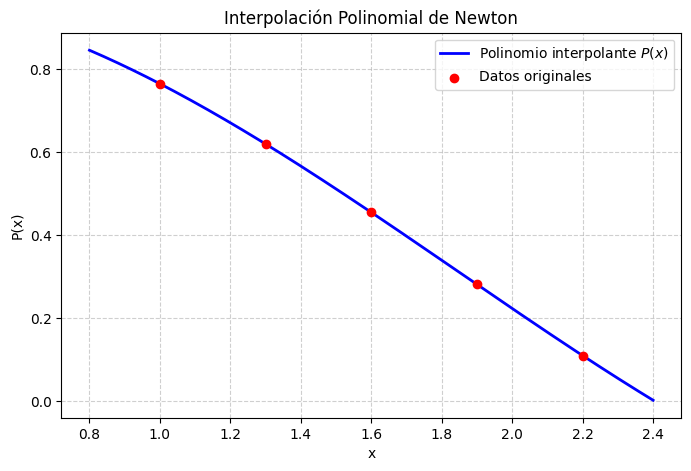

In [9]:
# Datos del Ejemplo 1 (página 94 de Burden)
x_ejemplo = [1.0, 1.3, 1.6, 1.9, 2.2]
y_ejemplo = [0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]

# 1. Obtenemos los coeficientes F_{i,i}
coefs = diferencias_divididas_newton(x_ejemplo, y_ejemplo)

print("Coeficientes de diferencias divididas (diagonal F_{i,i}):")
for i, c in enumerate(coefs):
    print(f"F[{i},{i}] = {c:.7f}")

print("-" * 50)

# 2. Construimos y graficamos el polinomio con la función corregida
P_x = construir_y_graficar_newton(x_ejemplo, y_ejemplo, coefs)


## <span style="color:#117864">Solución Final</span>

Los coeficientes obtenidos de la diagonal principal $F_{i,i}$ son:
* $F_{0,0} = 0.7651977$
* $F_{1,1} = -0.4837057$
* $F_{2,2} = -0.1087339$
* $F_{3,3} = 0.0658784$
* $F_{4,4} = 0.0018251$

**Polinomio Interpolante Final:**
$$P_4(x) = 0.0018251x^4 + 0.0552928x^3 - 0.3430466x^2 + 0.0733913x + 0.9777350$$